Local file 'City_Air_Quality.csv' not found. Creating a sample air quality dataset for demonstration...

Initial DataFrame Head:
        Date  AQI      PM2.5        PM10        CO
0 2025-01-01  147  27.534477   41.719775  2.635366
1 2025-01-02  137  74.817316   97.530086  0.822009
2 2025-01-03   59  47.575360   89.780931  1.822957
3 2025-01-04  151  29.655187   49.367347  2.348276
4 2025-01-05  116  59.335277  138.142428  2.803405

Columns found: ['Date', 'AQI', 'PM2.5', 'PM10', 'CO']


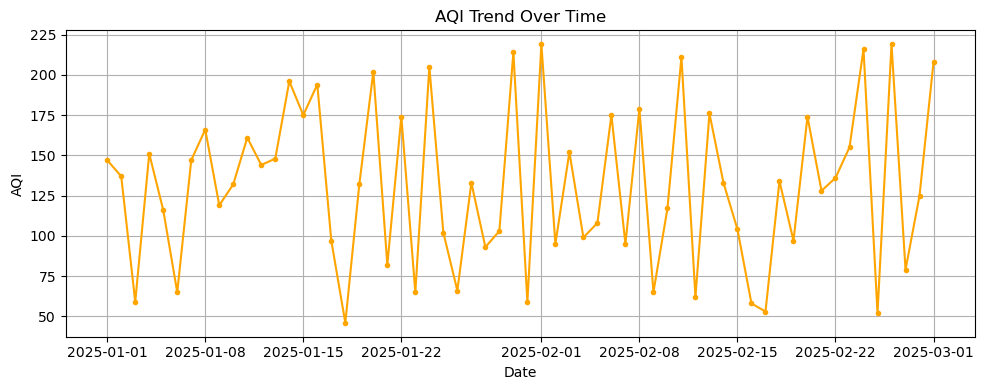

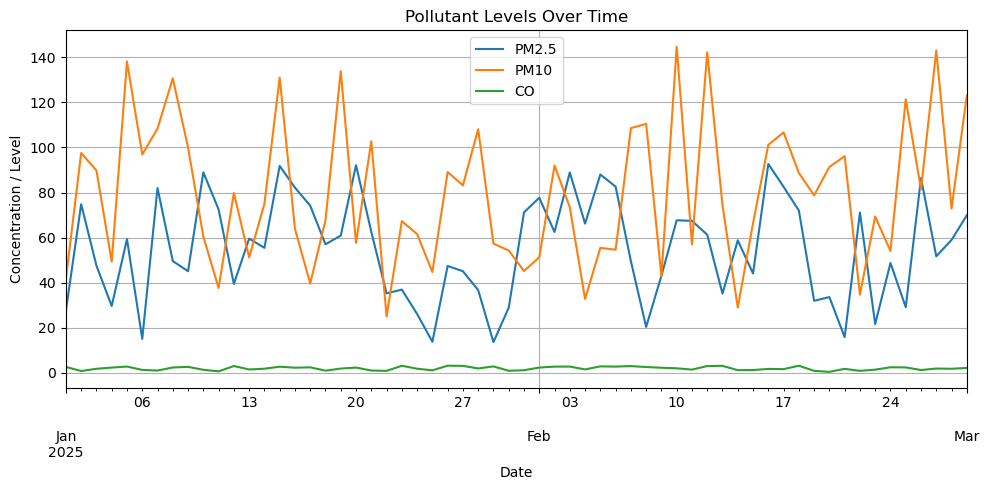

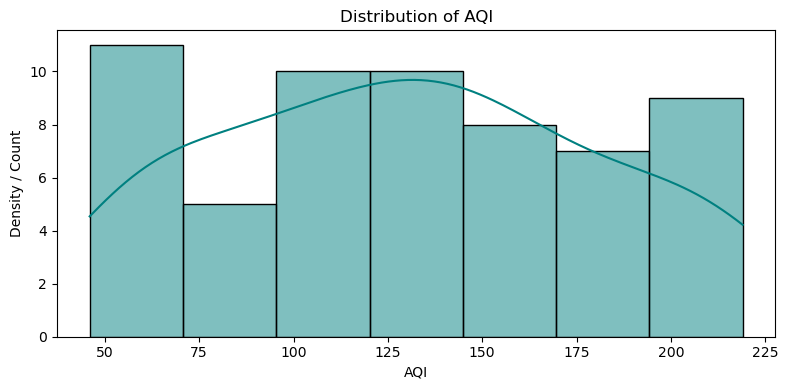

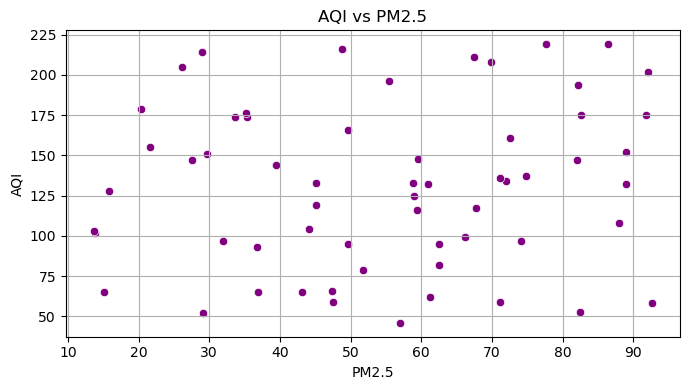

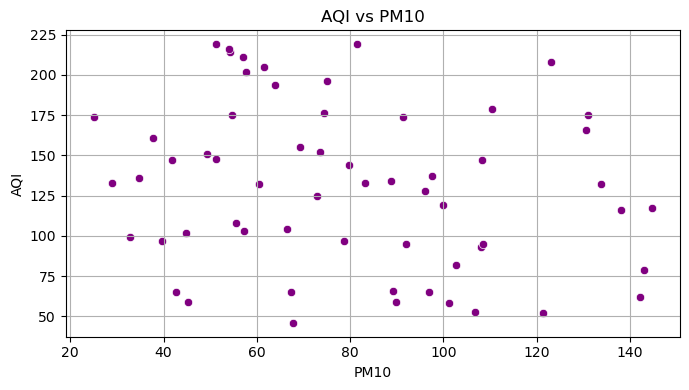

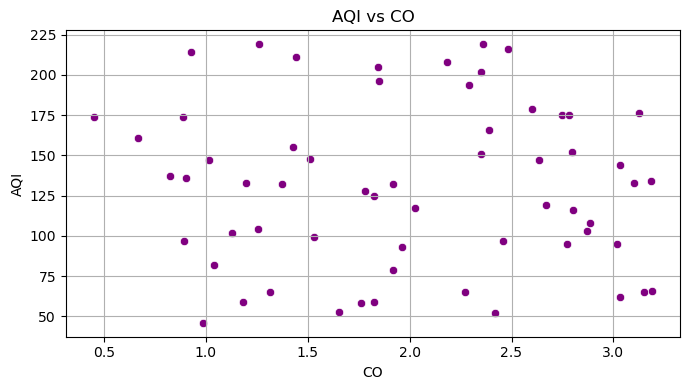

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = pd.read_csv("City_Air_Quality.csv")
    print("Successfully loaded 'City_Air_Quality.csv' from local storage.")
except FileNotFoundError:
    print("Local file 'City_Air_Quality.csv' not found. Creating a sample air quality dataset for demonstration...")
    np.random.seed(42)
    dates = pd.date_range(start="2025-01-01", periods=60, freq="D")
    data = {
        "Date": dates,
        "AQI": np.random.randint(45, 220, size=60),
        "PM2.5": np.random.uniform(12.5, 95.0, size=60),
        "PM10": np.random.uniform(25.0, 145.0, size=60),
        "CO": np.random.uniform(0.4, 3.2, size=60)
    }
    df = pd.DataFrame(data)

print("\nInitial DataFrame Head:")
print(df.head())
print("\nColumns found:", df.columns.tolist())

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
for col in ["AQI", "PM2.5", "PM10", "CO"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["Date"]).sort_values("Date")
if "AQI" in df.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(df["Date"], df["AQI"], marker=".", color="orange", linestyle="-")
    plt.title("AQI Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
pollutants = [c for c in ["PM2.5", "PM10", "CO"] if c in df.columns]
if pollutants:
    df.plot(x="Date", y=pollutants, figsize=(10, 5), title="Pollutant Levels Over Time")
    plt.ylabel("Concentration / Level")
    plt.xlabel("Date")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

if "AQI" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df["AQI"].dropna(), kde=True, color="teal")
    plt.title("Distribution of AQI")
    plt.xlabel("AQI")
    plt.ylabel("Density / Count")
    plt.tight_layout()
    plt.show()

for col in pollutants:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x=col, y="AQI", color="purple")
    plt.title(f"AQI vs {col}")
    plt.xlabel(col)
    plt.ylabel("AQI")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
Name - Devesh Mulani
Roll number - 4141